# Mini project การตรวจวินิจฉัยโรคของพืชจากภาพถ่ายด้วยระบบปัญญาประดิษฐ์เพื่อช่วยจำแนกโรคที่เกิดขึ้นบนใบพืช
### นายปฐมพงศ์ ศิริสวัสดิ์ 6710110239


In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# บังคับรันบน CPU
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


In [11]:
# กำหนด Path ไปที่โฟลเดอร์ Dataset 
DATA_DIR = Path(r"E:\3-1-2569\240-318\AI Project\PlantVillage")
folders = [x for x in DATA_DIR.iterdir() if x.is_dir()]
print("จำนวน Class:", len(folders))

จำนวน Class: 39


In [12]:
total_images = 0
for folder in folders:
    num_images = len(list(folder.iterdir()))
    total_images += num_images
    print(f"{folder.name} : {num_images} รูป")
print("-" * 40)
print(f"รวมจำนวนรูปภาพทั้งหมด: {total_images} รูป")

Apple___Apple_scab : 630 รูป
Apple___Black_rot : 621 รูป
Apple___Cedar_apple_rust : 275 รูป
Apple___healthy : 1645 รูป
Background_without_leaves : 1143 รูป
Blueberry___healthy : 1502 รูป
Cherry___healthy : 854 รูป
Cherry___Powdery_mildew : 1052 รูป
Corn___Cercospora_leaf_spot Gray_leaf_spot : 513 รูป
Corn___Common_rust : 1192 รูป
Corn___healthy : 1162 รูป
Corn___Northern_Leaf_Blight : 985 รูป
Grape___Black_rot : 1180 รูป
Grape___Esca_(Black_Measles) : 1383 รูป
Grape___healthy : 423 รูป
Grape___Leaf_blight_(Isariopsis_Leaf_Spot) : 1076 รูป
Orange___Haunglongbing_(Citrus_greening) : 5507 รูป
Peach___Bacterial_spot : 2297 รูป
Peach___healthy : 360 รูป
Pepper,_bell___Bacterial_spot : 997 รูป
Pepper,_bell___healthy : 1478 รูป
Potato___Early_blight : 1000 รูป
Potato___healthy : 152 รูป
Potato___Late_blight : 1000 รูป
Raspberry___healthy : 371 รูป
Soybean___healthy : 5090 รูป
Squash___Powdery_mildew : 1835 รูป
Strawberry___healthy : 456 รูป
Strawberry___Leaf_scorch : 1109 รูป
Tomato___Bacteri

In [13]:
extensions = {".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"}
filepaths = []
labels = []

for folder in sorted(folders):
    for file in folder.rglob("*"):
        if file.suffix in extensions:
            filepaths.append(str(file))
            labels.append(folder.name)

df = pd.DataFrame({
    "filepath": filepaths,
    "label": labels
})

print("จำนวนภาพทั้งหมด:", len(df))
print("จำนวน Class:", df["label"].nunique())

จำนวนภาพทั้งหมด: 55448
จำนวน Class: 39


In [14]:
class_names = sorted(df["label"].unique())
class_to_index = {name: i for i, name in enumerate(class_names)}
df["label_id"] = df["label"].map(class_to_index)
num_classes = len(class_names)
print("จำนวน Class:", num_classes)

จำนวน Class: 39


In [15]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["label"])
train_df, val_df = train_test_split(train_df, test_size=0.2, random_state=42, stratify=train_df["label"])
print("Train:", len(train_df))
print("Val:", len(val_df))
print("Test:", len(test_df))

Train: 35486
Val: 8872
Test: 11090


##### Preprocessing

In [16]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
datagen = ImageDataGenerator(rescale=1./255)
train_gen = datagen.flow_from_dataframe(
    train_df, x_col="filepath", y_col="label",
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical"
)
val_gen = datagen.flow_from_dataframe(
    val_df, x_col="filepath", y_col="label",
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", shuffle=False
)
test_gen = datagen.flow_from_dataframe(
    test_df, x_col="filepath", y_col="label",
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", shuffle=False
)

Found 35486 validated image filenames belonging to 39 classes.
Found 8872 validated image filenames belonging to 39 classes.
Found 11090 validated image filenames belonging to 39 classes.


##### CNN

In [18]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Conv2D(16, 3, padding='same', activation='relu', input_shape=(128, 128, 3)),
    layers.MaxPooling2D(),
    
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │     1,048,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 39)             │         2,535 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,074,759 (4.10 MB)

 Trainable params: 1,074,759 (4.10 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
epochs = 5

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=epochs
)

Epoch 1/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 477s 429ms/step - accuracy: 0.5743 - loss: 1.5559 - val_accuracy: 0.7557 - val_loss: 0.8216
Epoch 2/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 209s 189ms/step - accuracy: 0.8056 - loss: 0.6321 - val_accuracy: 0.8239 - val_loss: 0.5752
Epoch 3/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 87s 79ms/step - accuracy: 0.8712 - loss: 0.4121 - val_accuracy: 0.8421 - val_loss: 0.4898
Epoch 4/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 80s 72ms/step - accuracy: 0.9099 - loss: 0.2808 - val_accuracy: 0.8853 - val_loss: 0.3850
Epoch 5/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 84s 76ms/step - accuracy: 0.9314 - loss: 0.2110 - val_accuracy: 0.8929 - val_loss: 0.3522


347/347 ━━━━━━━━━━━━━━━━━━━━ 92s 266ms/step - accuracy: 0.8894 - loss: 0.3682
Test Accuracy: 88.94%


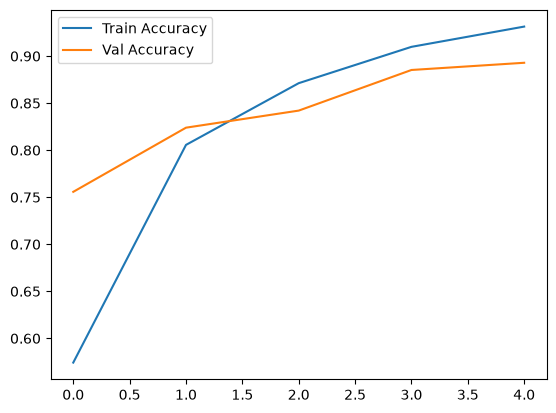

In [10]:
loss, acc = model.evaluate(test_gen)
print(f"Test Accuracy: {acc*100:.2f}%")
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.show()

In [12]:
cnn_test_loss, cnn_test_acc = model.evaluate(
    test_gen,
    verbose=1
)

cnn_val_loss, cnn_val_acc = model.evaluate(
    val_gen,
    verbose=1
)

print(f"CNN Validation Accuracy: {cnn_val_acc * 100:.2f}%")
print(f"CNN Test Accuracy: {cnn_test_acc * 100:.2f}%")

347/347 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.8894 - loss: 0.3682
278/278 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - accuracy: 0.8929 - loss: 0.3522
CNN Validation Accuracy: 89.29%
CNN Test Accuracy: 88.94%


In [13]:
model.save("cnn_baseline.keras")
print("บันทึก CNN Baseline")

บันทึก CNN Baseline


##### MobileNetV2

In [19]:
mobilenet_train_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True
)

mobilenet_val_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input
)

mobilenet_test_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input
)

In [20]:
mobilenet_train_gen = mobilenet_train_datagen.flow_from_dataframe(
    train_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

mobilenet_val_gen = mobilenet_val_datagen.flow_from_dataframe(
    val_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

mobilenet_test_gen = mobilenet_test_datagen.flow_from_dataframe(
    test_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 35486 validated image filenames belonging to 39 classes.
Found 8872 validated image filenames belonging to 39 classes.
Found 11090 validated image filenames belonging to 39 classes.


In [21]:
mobilenet_base = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3)
)

mobilenet_base.trainable = False

mobilenet_model = tf.keras.Sequential([
    tf.keras.Input(shape=(128, 128, 3)),
    mobilenet_base,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(
        num_classes,
        activation="softmax"
    )
])

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 39)             │        49,959 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,307,943 (8.80 MB)

 Trainable params: 49,959 (195.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [17]:
callbacks_mobilenet = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=3,
        mode="max",
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    )
]

history_mobilenet = mobilenet_model.fit(
    mobilenet_train_gen,
    validation_data=mobilenet_val_gen,
    epochs=5,
    callbacks=callbacks_mobilenet
)

Epoch 1/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 648s 582ms/step - accuracy: 0.7912 - loss: 0.7111 - val_accuracy: 0.8868 - val_loss: 0.3599 - learning_rate: 0.0010
Epoch 2/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 222s 200ms/step - accuracy: 0.8818 - loss: 0.3640 - val_accuracy: 0.8938 - val_loss: 0.3245 - learning_rate: 0.0010
Epoch 3/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 232s 209ms/step - accuracy: 0.8971 - loss: 0.3184 - val_accuracy: 0.9044 - val_loss: 0.3007 - learning_rate: 0.0010
Epoch 4/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 222s 200ms/step - accuracy: 0.9017 - loss: 0.3043 - val_accuracy: 0.9147 - val_loss: 0.2699 - learning_rate: 0.0010
Epoch 5/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 224s 202ms/step - accuracy: 0.9054 - loss: 0.2939 - val_accuracy: 0.9203 - val_loss: 0.2499 - learning_rate: 0.0010


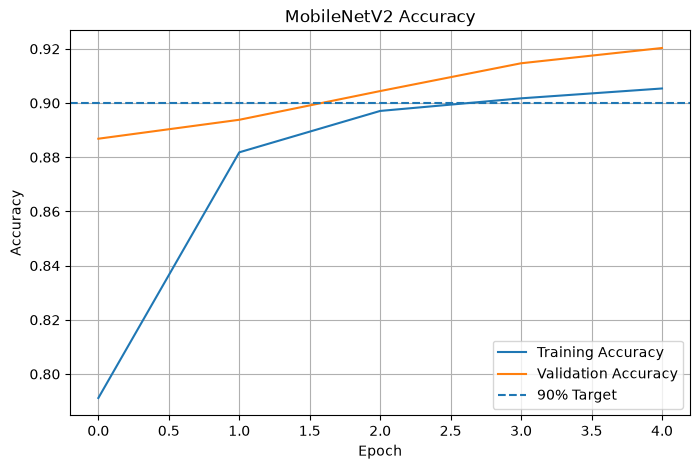

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(
    history_mobilenet.history["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    history_mobilenet.history["val_accuracy"],
    label="Validation Accuracy"
)
plt.axhline(
    0.90,
    linestyle="--",
    label="90% Target"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV2 Accuracy")
plt.legend()
plt.grid()
plt.show()

In [19]:
mobilenet_val_loss, mobilenet_val_acc = mobilenet_model.evaluate(
    mobilenet_val_gen,
    verbose=1
)
mobilenet_test_loss, mobilenet_test_acc = mobilenet_model.evaluate(
    mobilenet_test_gen,
    verbose=1
)
print(f"MobileNetV2 Validation Accuracy: {mobilenet_val_acc * 100:.2f}%")
print(f"MobileNetV2 Test Accuracy: {mobilenet_test_acc * 100:.2f}%")

278/278 ━━━━━━━━━━━━━━━━━━━━ 42s 151ms/step - accuracy: 0.9203 - loss: 0.2499
347/347 ━━━━━━━━━━━━━━━━━━━━ 49s 140ms/step - accuracy: 0.9268 - loss: 0.2250
MobileNetV2 Validation Accuracy: 92.03%
MobileNetV2 Test Accuracy: 92.68%


In [22]:
mobilenet_base.trainable = True

for layer in mobilenet_base.layers[:-30]:
    layer.trainable = False

for layer in mobilenet_base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

In [23]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [22]:
history_mobilenet_ft = mobilenet_model.fit(
    mobilenet_train_gen,
    validation_data=mobilenet_val_gen,
    epochs=5,
    callbacks=callbacks_mobilenet
)

Epoch 1/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 253s 225ms/step - accuracy: 0.9258 - loss: 0.2265 - val_accuracy: 0.9326 - val_loss: 0.2125 - learning_rate: 1.0000e-05
Epoch 2/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 252s 227ms/step - accuracy: 0.9357 - loss: 0.1913 - val_accuracy: 0.9365 - val_loss: 0.1959 - learning_rate: 1.0000e-05
Epoch 3/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 250s 225ms/step - accuracy: 0.9446 - loss: 0.1631 - val_accuracy: 0.9440 - val_loss: 0.1739 - learning_rate: 1.0000e-05
Epoch 4/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 251s 226ms/step - accuracy: 0.9498 - loss: 0.1502 - val_accuracy: 0.9462 - val_loss: 0.1757 - learning_rate: 1.0000e-05
Epoch 5/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 257s 232ms/step - accuracy: 0.9542 - loss: 0.1338 - val_accuracy: 0.9523 - val_loss: 0.1552 - learning_rate: 1.0000e-05


In [23]:
mobilenet_ft_loss, mobilenet_ft_acc = mobilenet_model.evaluate(
    mobilenet_test_gen,
    verbose=1
)

print(
    f"MobileNetV2 Fine-tuned Test Accuracy: "
    f"{mobilenet_ft_acc * 100:.2f}%"
)

347/347 ━━━━━━━━━━━━━━━━━━━━ 47s 135ms/step - accuracy: 0.9547 - loss: 0.1401
MobileNetV2 Fine-tuned Test Accuracy: 95.47%


In [24]:
mobilenet_model.save(
    "mobilenetv2_plant_disease.keras"
)

print("บันทึก MobileNetV2")

บันทึก MobileNetV2


##### EfficientNetB0

In [24]:
efficientnet_train_datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True
)
efficientnet_val_datagen = ImageDataGenerator()
efficientnet_test_datagen = ImageDataGenerator()

In [25]:
efficientnet_train_gen = efficientnet_train_datagen.flow_from_dataframe(
    train_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=42
)
efficientnet_val_gen = efficientnet_val_datagen.flow_from_dataframe(
    val_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)
efficientnet_test_gen = efficientnet_test_datagen.flow_from_dataframe(
    test_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 35486 validated image filenames belonging to 39 classes.
Found 8872 validated image filenames belonging to 39 classes.
Found 11090 validated image filenames belonging to 39 classes.


In [26]:
import os

model_files = [
    "cnn_baseline.keras",
    "mobilenetv2_plant_disease.keras",
    "efficientnetb0_plant_disease.keras"
]

for file in model_files:
    print(file, "->", os.path.exists(file))

cnn_baseline.keras -> True
mobilenetv2_plant_disease.keras -> True
efficientnetb0_plant_disease.keras -> True


In [27]:
efficientnet_base = tf.keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3)
)
efficientnet_base.trainable = False
efficientnet_model = tf.keras.Sequential([
    tf.keras.Input(shape=(128, 128, 3)),
    efficientnet_base,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(
        num_classes,
        activation="softmax"
    )
])
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
efficientnet_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 39)             │        49,959 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,099,530 (15.64 MB)

 Trainable params: 49,959 (195.15 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [28]:
callbacks_efficientnet = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=3,
        mode="max",
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    )
]
history_efficientnet = efficientnet_model.fit(
    efficientnet_train_gen,
    validation_data=efficientnet_val_gen,
    epochs=5,
    callbacks=callbacks_efficientnet
)

Epoch 1/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 281s 248ms/step - accuracy: 0.7656 - loss: 0.8912 - val_accuracy: 0.8700 - val_loss: 0.4821 - learning_rate: 0.0010
Epoch 2/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 246s 221ms/step - accuracy: 0.8653 - loss: 0.4563 - val_accuracy: 0.8964 - val_loss: 0.3626 - learning_rate: 0.0010
Epoch 3/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 270s 244ms/step - accuracy: 0.8852 - loss: 0.3754 - val_accuracy: 0.9050 - val_loss: 0.3181 - learning_rate: 0.0010
Epoch 4/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 333s 300ms/step - accuracy: 0.8919 - loss: 0.3449 - val_accuracy: 0.9048 - val_loss: 0.3024 - learning_rate: 0.0010
Epoch 5/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 293s 264ms/step - accuracy: 0.8982 - loss: 0.3204 - val_accuracy: 0.9092 - val_loss: 0.2812 - learning_rate: 0.0010


In [35]:
efficientnet_val_loss, efficientnet_val_acc = efficientnet_model.evaluate(
    efficientnet_val_gen,
    verbose=1
)
efficientnet_test_loss, efficientnet_test_acc = efficientnet_model.evaluate(
    efficientnet_test_gen,
    verbose=1
)
print(
    f"EfficientNetB0 Validation Accuracy: "
    f"{efficientnet_val_acc * 100:.2f}%"
)
print(
    f"EfficientNetB0 Test Accuracy: "
    f"{efficientnet_test_acc * 100:.2f}%"
)

278/278 ━━━━━━━━━━━━━━━━━━━━ 58s 200ms/step - accuracy: 0.9498 - loss: 0.1530
347/347 ━━━━━━━━━━━━━━━━━━━━ 64s 184ms/step - accuracy: 0.9546 - loss: 0.1411
EfficientNetB0 Validation Accuracy: 94.98%
EfficientNetB0 Test Accuracy: 95.46%


In [28]:
efficientnet_base.trainable = True
for layer in efficientnet_base.layers[:-30]:
    layer.trainable = False
for layer in efficientnet_base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

In [29]:
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [32]:
history_efficientnet_ft = efficientnet_model.fit(
    efficientnet_train_gen,
    validation_data=efficientnet_val_gen,
    epochs=5,
    callbacks=callbacks_efficientnet
)

Epoch 1/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 348s 305ms/step - accuracy: 0.9150 - loss: 0.2577 - val_accuracy: 0.9335 - val_loss: 0.2029 - learning_rate: 1.0000e-05
Epoch 2/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 674s 608ms/step - accuracy: 0.9274 - loss: 0.2214 - val_accuracy: 0.9385 - val_loss: 0.1893 - learning_rate: 1.0000e-05
Epoch 3/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 434s 392ms/step - accuracy: 0.9336 - loss: 0.2024 - val_accuracy: 0.9423 - val_loss: 0.1729 - learning_rate: 1.0000e-05
Epoch 4/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 308s 278ms/step - accuracy: 0.9379 - loss: 0.1888 - val_accuracy: 0.9462 - val_loss: 0.1649 - learning_rate: 1.0000e-05
Epoch 5/5
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 303s 273ms/step - accuracy: 0.9418 - loss: 0.1754 - val_accuracy: 0.9498 - val_loss: 0.1530 - learning_rate: 1.0000e-05


In [33]:
efficientnet_ft_loss, efficientnet_ft_acc = efficientnet_model.evaluate(
    efficientnet_test_gen,
    verbose=1
)

print(
    f"EfficientNetB0 Fine-tuned Test Accuracy: "
    f"{efficientnet_ft_acc * 100:.2f}%"
)

347/347 ━━━━━━━━━━━━━━━━━━━━ 163s 471ms/step - accuracy: 0.9546 - loss: 0.1411
EfficientNetB0 Fine-tuned Test Accuracy: 95.46%


In [34]:
efficientnet_model.save(
    "efficientnetb0_plant_disease.keras"
)
print("บันทึก EfficientNetB0")

บันทึก EfficientNetB0


##### โหลดโมเดล

In [33]:
cnn_model = tf.keras.models.load_model(
    "cnn_baseline.keras"
)
mobilenet_model = tf.keras.models.load_model(
    "mobilenetv2_plant_disease.keras"
)
efficientnet_model = tf.keras.models.load_model(
    "efficientnetb0_plant_disease.keras"
)
print("โหลด Model เรียบร้อย")

โหลด Model เรียบร้อย


In [15]:
cnn_val_loss, cnn_val_acc = cnn_model.evaluate(
    val_gen,
    verbose=0
)
cnn_test_loss, cnn_test_acc = cnn_model.evaluate(
    test_gen,
    verbose=0
)
mobilenet_val_loss, mobilenet_val_acc = mobilenet_model.evaluate(
    mobilenet_val_gen,
    verbose=0
)
mobilenet_test_loss, mobilenet_test_acc = mobilenet_model.evaluate(
    mobilenet_test_gen,
    verbose=0
)
efficientnet_val_loss, efficientnet_val_acc = efficientnet_model.evaluate(
    efficientnet_val_gen,
    verbose=0
)
efficientnet_test_loss, efficientnet_test_acc = efficientnet_model.evaluate(
    efficientnet_test_gen,
    verbose=0
)
print(f"CNN Validation Accuracy: {cnn_val_acc * 100:.2f}%")
print(f"CNN Test Accuracy: {cnn_test_acc * 100:.2f}%")
print(f"MobileNetV2 Validation Accuracy: {mobilenet_val_acc * 100:.2f}%")
print(f"MobileNetV2 Test Accuracy: {mobilenet_test_acc * 100:.2f}%")
print(f"EfficientNetB0 Validation Accuracy: {efficientnet_val_acc * 100:.2f}%")
print(f"EfficientNetB0 Test Accuracy: {efficientnet_test_acc * 100:.2f}%")

CNN Validation Accuracy: 89.29%
CNN Test Accuracy: 88.94%
MobileNetV2 Validation Accuracy: 95.23%
MobileNetV2 Test Accuracy: 95.47%
EfficientNetB0 Validation Accuracy: 94.98%
EfficientNetB0 Test Accuracy: 95.46%


In [16]:
results = pd.DataFrame({
    "Model": [
        "CNN",
        "MobileNetV2",
        "EfficientNetB0"
    ],
    "Validation Accuracy (%)": [
        cnn_val_acc * 100,
        mobilenet_val_acc * 100,
        efficientnet_val_acc * 100
    ],
    "Test Accuracy (%)": [
        cnn_test_acc * 100,
        mobilenet_test_acc * 100,
        efficientnet_test_acc * 100
    ]
})

results

,Model,Validation Accuracy (%),Test Accuracy (%)
0,CNN,89.292157,88.944995
1,MobileNetV2,95.232189,95.473397
2,EfficientNetB0,94.984221,95.455366


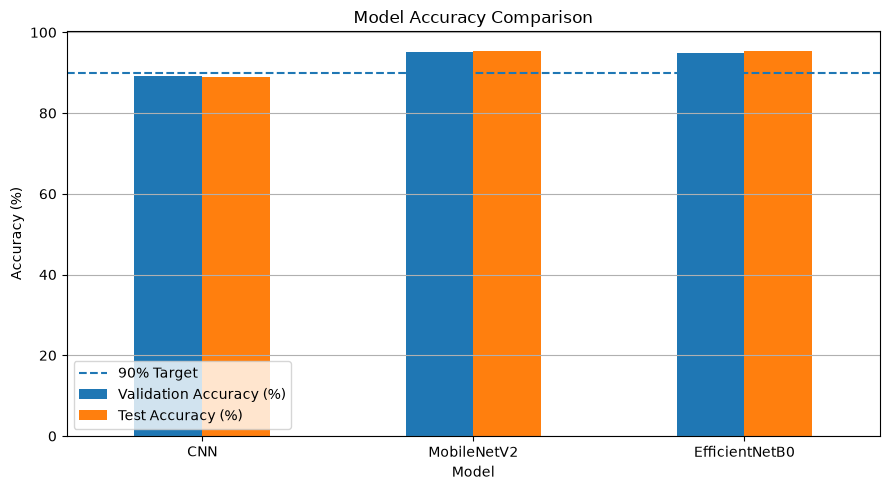

In [17]:
results_plot = results.set_index("Model")
results_plot.plot(
    kind="bar",
    figsize=(9, 5)
)
plt.axhline(
    90,
    linestyle="--",
    label="90% Target"
)
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [18]:
efficientnet_test_gen.reset()
predictions = efficientnet_model.predict(
    efficientnet_test_gen,
    verbose=1
)
y_pred = np.argmax(
    predictions,
    axis=1
)
y_true = efficientnet_test_gen.classes
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

347/347 ━━━━━━━━━━━━━━━━━━━━ 83s 235ms/step
                                               precision    recall  f1-score   support

                           Apple___Apple_scab       0.97      0.79      0.87       126
                            Apple___Black_rot       0.91      0.98      0.95       124
                     Apple___Cedar_apple_rust       1.00      0.96      0.98        55
                              Apple___healthy       0.93      0.96      0.95       329
                    Background_without_leaves       1.00      0.98      0.99       229
                          Blueberry___healthy       0.98      0.99      0.98       300
                      Cherry___Powdery_mildew       1.00      0.99      1.00       210
                             Cherry___healthy       0.95      0.99      0.97       171
   Corn___Cercospora_leaf_spot Gray_leaf_spot       0.87      0.80      0.83       103
                           Corn___Common_rust       1.00      0.99      0.99       23

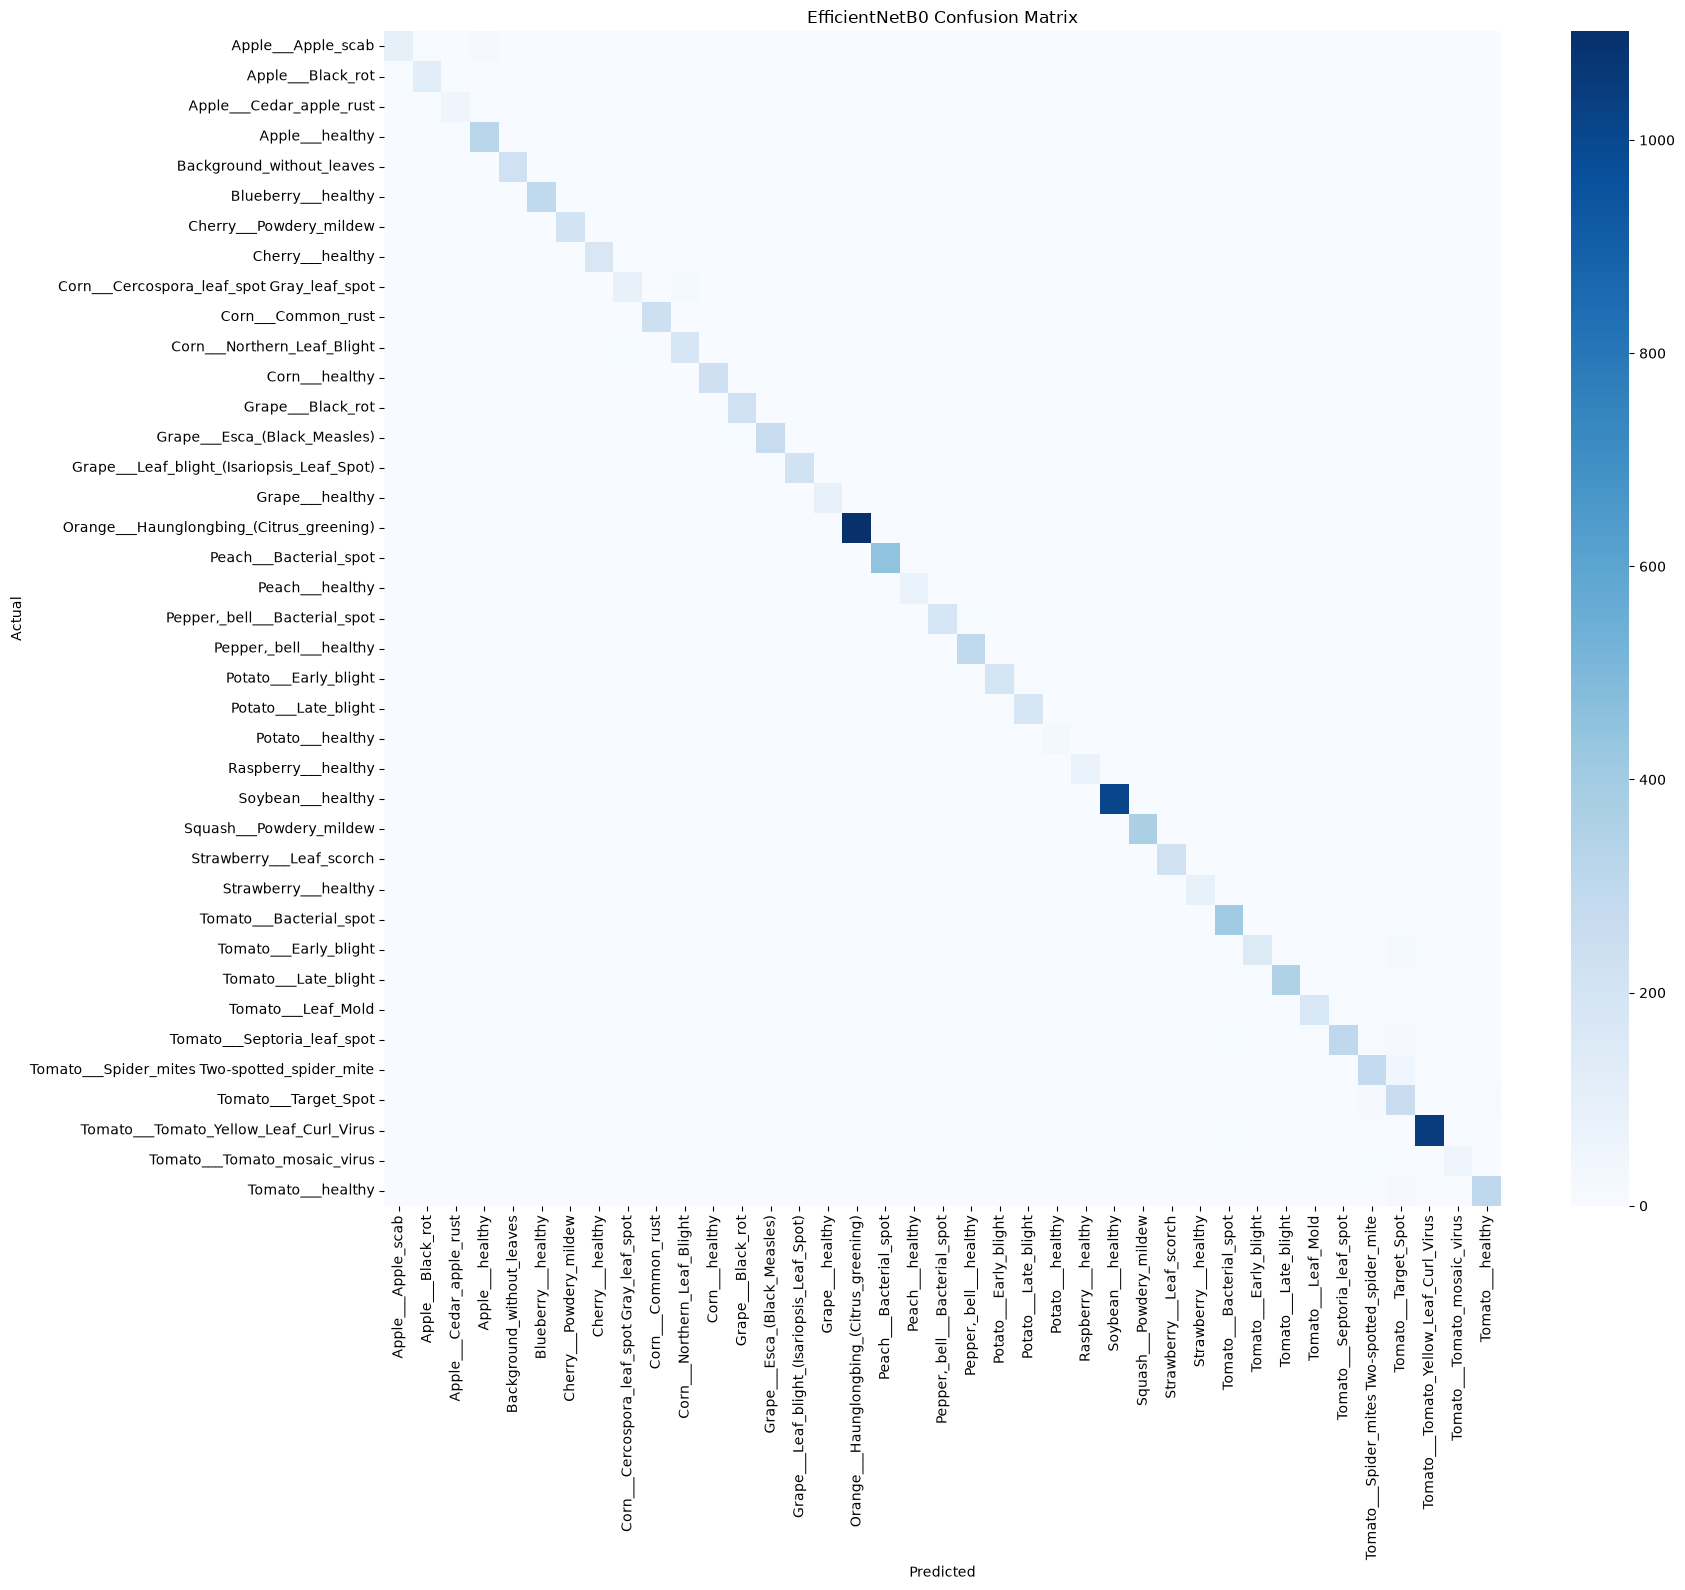

In [19]:
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(18, 16))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("EfficientNetB0 Confusion Matrix")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [42]:
def predict_plant_disease_mobilenet(img_path):

    img = tf.keras.utils.load_img(
        img_path,
        target_size=(128, 128)
    )

    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)

    img_array = tf.keras.applications.mobilenet_v2.preprocess_input(
        img_array
    )

    predictions = mobilenet_model.predict(
        img_array,
        verbose=0
    )

    score = predictions[0]

    class_idx = np.argmax(score)
    predicted_class = class_names[class_idx]
    confidence = 100 * np.max(score)

    parts = predicted_class.split("___")

    plant_type = parts[0] if len(parts) > 1 else "ไม่ทราบชนิดพืช"
    disease = parts[1].replace("_", " ") if len(parts) > 1 else predicted_class

    if disease.lower() == "healthy":
        status = "พืชปกติ แข็งแรงดี"
        advice = "ดูแลรักษาตามปกติต่อไป"
        disease = "ปกติ (Healthy)"
    else:
        status = "มีแนวโน้มติดโรค"
        advice = "ควรตรวจสอบบริเวณใบเพิ่มเติมและดำเนินการจัดการโรคตามแนวทางที่เหมาะสม"

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

    print("--- ผลการวิเคราะห์ภาพ ---")
    print(f"ชนิดพืช: {plant_type}")
    print(f"ผลการตรวจ: {disease}")
    print(f"ความมั่นใจ: {confidence:.2f}%")
    print(f"สถานะ: {status}")
    print(f"คำแนะนำ: {advice}")

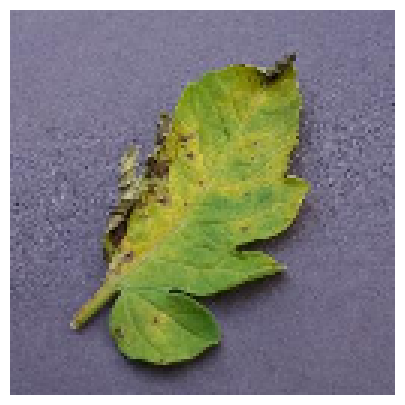

--- ผลการวิเคราะห์ภาพ ---
ชนิดพืช: Tomato
ผลการตรวจ: Septoria leaf spot
ความมั่นใจ: 94.06%
สถานะ: มีแนวโน้มติดโรค
คำแนะนำ: ควรตรวจสอบบริเวณใบเพิ่มเติมและดำเนินการจัดการโรคตามแนวทางที่เหมาะสม


In [34]:
predict_plant_disease_mobilenet(
    test_df.iloc[11]["filepath"]
)

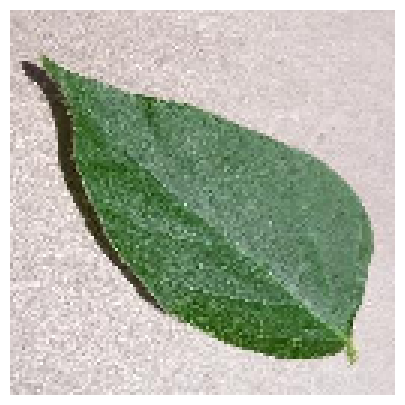

--- ผลการวิเคราะห์ภาพ ---
ชนิดพืช: Soybean
ผลการตรวจ: ปกติ (Healthy)
ความมั่นใจ: 99.57%
สถานะ: พืชปกติ แข็งแรงดี
คำแนะนำ: ดูแลรักษาตามปกติต่อไป


In [35]:
predict_plant_disease_mobilenet(
    test_df.iloc[7757]["filepath"]
)